# Step 3: Feature-engineering improvements

Each change from `experiments/02_`–`10_` against the LightGBM baseline. MiniLM rows are pretrained and shown for reference only. Details: `docs/steps/03_feature_engineering.md`.

In [1]:
# Imports and paths
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
import nbutils as U
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("model prediction groups found:", len(list(U.PRED_DIR.glob("*/sarc_random__test.parquet"))))

model prediction groups found: 22


In [2]:
# Metrics and bootstrap for each change
STEP = ["lgbm_reply_tfidf_surface", "lgbm_cues", "lgbm_contrast", "lgbm_cues_contrast", "lr_word_char_surface",
        "nblr_word_char_surface", "lgbm_lsa", "lgbm_cues_contrast_lsa", "lgbm_lrscore", "lgbm_lrscore_cues_contrast",
        "lgbm_v60k_cues_contrast", "lgbm_minilm_v60k_cues_contrast", "lgbm_combined_best"]
test, val = U.predictions("sarc_random"); ts, vs = U.predictions("sarc_subreddit")
a = U.evaluate(test, val, STEP); b = U.evaluate(ts, vs, STEP)
d = U.bootstrap_vs(test, STEP)
tab = (a[["model", "label", "compliant", "roc_auc", "p75_recall"]]
       .merge(d[["model", "d_auc", "ci_low", "ci_high"]], on="model", how="left")
       .merge(b[["model", "roc_auc"]].rename(columns={"roc_auc": "subreddit_auc"}), on="model", how="left"))
U.show(tab)

,model,label,compliant,roc_auc,p75_recall,d_auc,ci_low,ci_high,subreddit_auc
0,lgbm_combined_best,"LightGBM, all features incl. MiniLM",False,0.8330,0.7585,0.0256,0.0241,0.0269,0.8251
1,lgbm_lrscore_cues_contrast,LightGBM + LR score + cues + contrast,True,0.8296,0.7512,0.0222,0.0209,0.0233,0.8226
2,lgbm_minilm_v60k_cues_contrast,LightGBM + MiniLM embeddings,False,0.8270,0.7487,0.0196,0.0181,0.0209,0.8208
3,lgbm_lrscore,LightGBM + LR score,True,0.8264,0.7466,0.0189,0.0180,0.0199,0.8187
4,lr_word_char_surface,"LR, word + char n-grams",True,0.8184,0.7290,0.0110,0.0097,0.0123,0.8101
5,nblr_word_char_surface,"NB-SVM, word + char n-grams",True,0.8169,0.7228,0.0095,0.0080,0.0108,0.8084
6,lgbm_v60k_cues_contrast,"LightGBM, 60k vocab + cues + contrast",True,0.8161,0.7217,0.0087,0.0077,0.0095,0.8099
7,lgbm_cues_contrast,LightGBM + cues + contrast,True,0.8143,0.7180,0.0069,0.0061,0.0076,0.8084
8,lgbm_cues,LightGBM + linguistic cues,True,0.8120,0.7142,0.0046,0.0039,0.0052,0.8068
9,lgbm_contrast,LightGBM + reply/parent contrast,True,0.8103,0.7067,0.0029,0.0023,0.0035,0.8050


## 3.1 Gains with 95% intervals

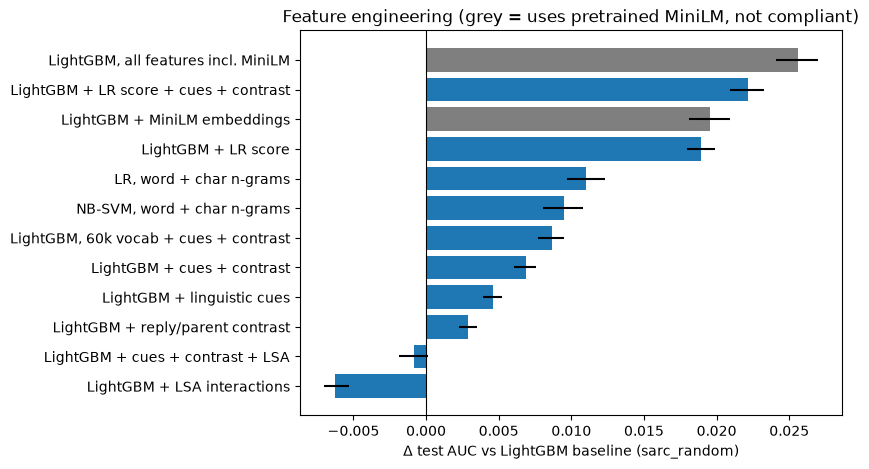

In [3]:
# Gains with 95% intervals
t = tab.dropna(subset=["d_auc"]).sort_values("d_auc")
fig, ax = plt.subplots(figsize=(7, 5))
colors = ["tab:blue" if c else "tab:gray" for c in t["compliant"]]
ax.barh(t["label"], t["d_auc"], xerr=[t["d_auc"] - t["ci_low"], t["ci_high"] - t["d_auc"]], color=colors)
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("Δ test AUC vs LightGBM baseline (sarc_random)")
ax.set_title("Feature engineering (grey = uses pretrained MiniLM, not compliant)")
U.savefig(fig, "S03_feature_gains.png"); plt.show()

## 3.2 Same gains on unseen communities?
If a feature only encoded topic, its gain would shrink on `sarc_subreddit`.

In [4]:
# Gain on both splits
base_r = a.set_index("model").loc["lgbm_reply_tfidf_surface", "roc_auc"]; base_s = b.set_index("model").loc["lgbm_reply_tfidf_surface", "roc_auc"]
g = tab.assign(gain_random=tab.roc_auc - base_r, gain_subreddit=tab.subreddit_auc - base_s)
U.show(g[["label", "gain_random", "gain_subreddit"]])

,label,gain_random,gain_subreddit
0,"LightGBM, all features incl. MiniLM",0.0256,0.0228
1,LightGBM + LR score + cues + contrast,0.0222,0.0203
2,LightGBM + MiniLM embeddings,0.0196,0.0185
3,LightGBM + LR score,0.0189,0.0164
4,"LR, word + char n-grams",0.0110,0.0078
5,"NB-SVM, word + char n-grams",0.0095,0.0061
6,"LightGBM, 60k vocab + cues + contrast",0.0087,0.0076
7,LightGBM + cues + contrast,0.0069,0.0061
8,LightGBM + linguistic cues,0.0046,0.0045
9,LightGBM + reply/parent contrast,0.0029,0.0027


## 3.3 How much the trees use the cue block

In [5]:
# Cue block usage
s = U.read_json(U.EXP / "02_linguistic_cues/results/summary.json")
for k in ["control", "cues"]:
    r = s[k]["sarc_random"]
    print(f"{s[k]['tag']:<16} features {r['n_features']:>6}  trees {r['n_trees']:>5}  val AUC {r['val_auc']:.4f}  "
          f"test AUC {r['sarc_random']['roc_auc']:.4f}  share of split gain from added block {s[k]['gain_share_extra']:.2f}")

lgbm_base_repro  features  20017  trees  1041  val AUC 0.8044  test AUC 0.8074  share of split gain from added block 0.00
lgbm_cues        features  20042  trees  1231  val AUC 0.8087  test AUC 0.8120  share of split gain from added block 0.21


In [6]:
# Save table
tab.to_csv(U.RESULTS / "step03_feature_engineering.csv", index=False)

## 3.4 Takeaways

- **Best compliant single model: LightGBM + LR score + cues + contrast, 0.8296 (+0.022).**
- The single largest compliant gain is feeding the out-of-fold word+char LR score to the trees (+0.019): trees handle non-linear surface cues, the LR covers the long n-gram tail.
- Character n-grams are cheap and strong: one LR reaches 0.818, above every original baseline.
- Explicit cues (+0.0045) and contrast features (+0.003) are small but identical on both splits, so they are not topic proxies.
- LSA interactions **hurt** (−0.006): dense low-information dimensions let the trees overfit.
- MiniLM rows are shown only to price pretraining; they are excluded from submitted results.